In [1]:
import pandas as pd
import urllib.request
import zipfile
import io

# Download the dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = urllib.request.urlopen(url)
zip_data = response.read()

# Open the downloaded ZIP file
with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
    filename = next(
        f for f in z.namelist()
        if f.endswith("SMSSpamCollection")
    )

    with z.open(filename) as file:
        data = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"]
        )

# Display the first five messages
print(data.head())

# Display dataset size
print("Dataset size:", data.shape)

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Dataset size: (5572, 2)


In [2]:
print(data["label"].value_counts())



label
ham     4825
spam     747
Name: count, dtype: int64


In [3]:
# Check for missing values
print(data.isnull().sum())

# Check for duplicate messages
print("Duplicate rows:", data.duplicated().sum())

label      0
message    0
dtype: int64
Duplicate rows: 403


In [4]:
# Remove duplicate rows
data = data.drop_duplicates()

# Check the dataset after cleaning
print("Dataset size after cleaning:", data.shape)

# Check spam and normal messages again
print(data["label"].value_counts())


Dataset size after cleaning: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


In [5]:
# Convert text labels into numbers
data["label_num"] = data["label"].map({
    "ham": 0,
    "spam": 1
})

# Display the result
print(data.head())

# Check the new labels
print(data["label_num"].value_counts())

  label                                            message  label_num
0   ham  Go until jurong point, crazy.. Available only ...          0
1   ham                      Ok lar... Joking wif u oni...          0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...          1
3   ham  U dun say so early hor... U c already then say...          0
4   ham  Nah I don't think he goes to usf, he lives aro...          0
label_num
0    4516
1     653
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

# Separate messages and labels
X = data["message"]
y = data["label_num"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert SMS text into numerical features
vectorizer = TfidfVectorizer(stop_words="english")

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)


Training data shape: (4135, 7414)
Testing data shape: (1034, 7414)


In [8]:
from sklearn.naive_bayes import MultinomialNB

# Create the machine learning model
model = MultinomialNB()

# Train the model using the training data
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict spam or normal messages
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Show detailed performance
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham (Normal)", "Spam"]
))

# Show confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 96.71 %

Classification Report:
              precision    recall  f1-score   support

Ham (Normal)       0.96      1.00      0.98       903
        Spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034

Confusion Matrix:
[[903   0]
 [ 34  97]]


In [10]:
def predict_sms(message):
    message_tfidf = vectorizer.transform([message])
    prediction = model.predict(message_tfidf)[0]

    if prediction == 1:
        print("Result: SPAM message")
    else:
        print("Result: NORMAL message")


predict_sms("Congratulations! You have won a free prize. Call now!")
predict_sms("Hey, are we meeting for lunch today?")

Result: SPAM message
Result: NORMAL message


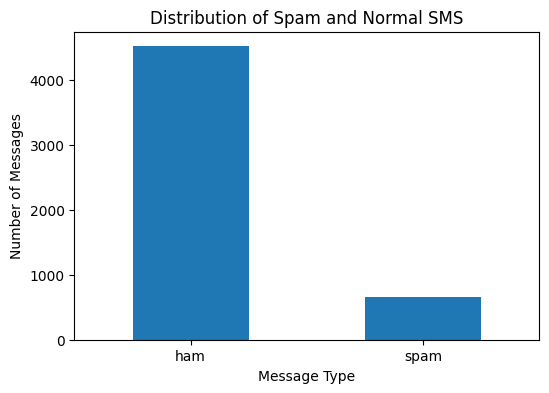

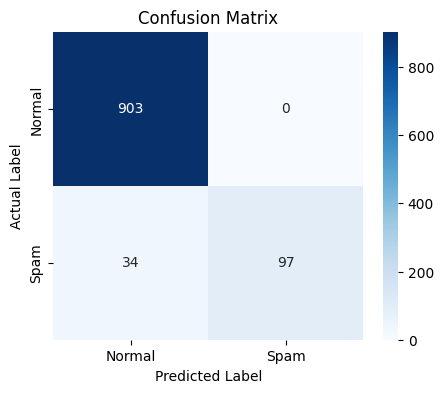

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Plot spam and normal message counts
plt.figure(figsize=(6, 4))
data["label"].value_counts().plot(kind="bar")
plt.title("Distribution of Spam and Normal SMS")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Spam"],
    yticklabels=["Normal", "Spam"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [12]:
!pip install gradio

In [18]:
import gradio as gr

suspicious_phrases = [
    "click link",
    "click below",
    "click the link",
    "verify now",
    "verify your account",
    "account blocked",
    "account suspended",
    "claim now",
    "claim your prize",
    "won a free prize",
    "free prize",
    "limited offer",
    "urgent action",
    "send otp",
    "share otp",
    "bank details",
    "cash reward",
    "winner",
    "congratulations",
    "free entry"
]

def check_message(message):
    if not message or not message.strip():
        return "⚠️ Enter a message first", "No message entered", "—"

    text = message.lower()

    # Machine Learning prediction
    message_vector = vectorizer.transform([message])
    prediction = model.predict(message_vector)[0]

    # Rule-based suspicious phrase checking
    suspicious = any(phrase in text for phrase in suspicious_phrases)

    # Combine ML and rule-based detection
    if prediction == 1 or suspicious:
        result = "🚨 SPAM / SUSPICIOUS MESSAGE"
        details = "Warning: This message may contain suspicious content. Do not click links or share personal information."
    else:
        result = "✅ NORMAL MESSAGE"
        details = "No obvious spam patterns were detected. Still be careful with unknown messages."

    # Confidence from the ML model
    probabilities = model.predict_proba(message_vector)[0]
    confidence = round(max(probabilities) * 100, 2)

    confidence_text = f"Model confidence: {confidence}%"

    return result, details, confidence_text


with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("# 📩 Spam Message Detector")
    gr.Markdown("### AI-powered SMS Spam Detection")
    gr.Markdown("Enter a message below to check whether it is spam or normal.")

    message_input = gr.Textbox(
        label="SMS Message",
        placeholder="Paste your SMS message here...",
        lines=4
    )

    check_button = gr.Button("🔍 Analyze Message", variant="primary")

    prediction_output = gr.Textbox(label="Detection Result")
    details_output = gr.Textbox(label="Security Advice")
    confidence_output = gr.Textbox(label="Model Confidence")

    check_button.click(
        fn=check_message,
        inputs=message_input,
        outputs=[prediction_output, details_output, confidence_output]
    )

    gr.Markdown("---")
    gr.Markdown("⚠️ This tool is for educational purposes. Always verify suspicious messages independently.")

demo.launch(share=True)

/tmp/ipykernel_542/3102127680.py:56: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0c892553bbf7f9f0af.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
